# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

**Ответ:**

Устройство - Kaggle, GPU Tesla T4. Финальный прогон с `FAST_MODE = False` шел на Kaggle в фоне, ноутбук выполнялся целиком сверху вниз, outputs сохранены в этом файле. По логу Kaggle весь прогон занял около 14 минут.

Модель - [ai-forever/ruBert-base](https://huggingface.co/ai-forever/ruBert-base), revision `05f37a2ca9e333fd18f30cd0c96c68d274793c69`, лицензия Apache-2.0.

Датасет - NEREL, загружаю из [iluvvatar/NEREL](https://huggingface.co/datasets/iluvvatar/NEREL) (parquet-версия, commit `f8b9d0fe89e7634d2bd4fa42b3ade48dad8697cd`). Исходник [nerel-ds/NEREL](https://github.com/nerel-ds/NEREL), статья [arXiv:2108.13112](https://arxiv.org/abs/2108.13112). Лицензия не указана ни в карточке на HF, ни в репозитории авторов (проверял 22.11.2026). Датасет опубликован авторами для исследований и есть в списке датасетов в задании 2.1. Беру только сущности, вложенные убираю (см. 2.2).

Бонусы 6.2, 6.3, 6.4, 6.5. 6.1 не делал.

Источники - документация transformers (token classification, `Trainer`), seqeval, документация PyTorch по динамической квантизации, статья NEREL. Нерешенных задач нет.

In [1]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib

  Installing build dependencies ... done


  Getting requirements to build wheel ... done


  Installing backend dependencies ... done


  Preparing metadata (pyproject.toml) ... done


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

torch 2.11.0+cu130, transformers 5.22.1, datasets 5.1.0
CUDA available: True


In [3]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

cuda Tesla T4


In [4]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.2', '6.3', '6.4', '6.5'}   # пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else None   # None - весь train
N_EVAL = 500 if FAST_MODE else None     # подмножество validation и test в FAST_MODE
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128                        # длина в сабвордах, длиннее - обрезается
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}

---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [5]:
os.environ['DISABLE_SAFETENSORS_CONVERSION'] = '1'
MODEL_ID = 'ai-forever/ruBert-base'
REVISION = '05f37a2ca9e333fd18f30cd0c96c68d274793c69'
TOKENIZER_KWARGS = {'do_lower_case': False}

In [6]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    ai-forever/ruBert-base
revision: 05f37a2ca9e333fd18f30cd0c96c68d274793c69
license:  apache-2.0
language: ['ru']
updated:  2023-11-03 12:50:38+00:00
weights:  {'pytorch_model.bin': '683 MB'}


config.json:   0%|          | 0.00/590 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.78M [00:00<?, ?B/s]

BertTokenizer vocab size 120138
['Петр', 'Ильич', 'Чайковский', 'родился', 'в', 'Вот', '##кинс', '##ке']


In [7]:
default_tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION)
print('без TOKENIZER_KWARGS:', default_tokenizer.tokenize('Чайковский'), '| do_lower_case =', default_tokenizer.do_lower_case)
print('с TOKENIZER_KWARGS:  ', tokenizer.tokenize('Чайковский'))
del default_tokenizer

без TOKENIZER_KWARGS: ['ча', '##ик', '##ов', '##ски', '##и'] | do_lower_case = True
с TOKENIZER_KWARGS:   ['Чайковский']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:** Взял `ai-forever/ruBert-base` от SberDevices. Это BERT-base под русский язык, 12 слоев, hidden 768, 178M параметров. Словарь на 120k сабвордов, в карточке написано BPE, но по `##` видно, что это WordPiece. Предобучали MLM на 30 ГБ русских текстов. NEREL - русские новости, так что язык и домен совпадают. Лицензия Apache-2.0. На T4 модель такого размера дообучается на 11k предложений за пару минут. По качеству ждал F1 по сущностям около 0.8, т к 29 типов и вложенность сильно сложнее трех типов Collection3.

`DeepPavlov/rubert-base-cased` той же архитектуры и размера (180M), значит и скорость та же. Учился на русской википедии и новостях, метрик NER в карточке нет, лицензия тоже не указана. `cointegrated/rubert-tiny2` в 6 раз меньше (29M), русский + английский, лицензия MIT. Он намного быстрее, но сделан под эмбеддинги предложений, и на NER у меня он вышел заметно слабее (6.2).

С токенизатором есть проблема. В репозитории модели нет `tokenizer_config.json`, и `AutoTokenizer` по умолчанию ставит `do_lower_case=True`. Тогда весь текст уходит в нижний регистр, а й превращается в и. «Чайковский» режется на `ча ##ик ##ов ##ски ##и`, хотя словарь регистрозависимый и слово в нем есть целиком (ячейка выше). Заглавная буква - один из главных признаков сущности, поэтому `TOKENIZER_KWARGS = {'do_lower_case': False}`.

Без `revision` через полгода `main` может указывать уже на другие веса или токенизатор. Например, владелец добавит `tokenizer_config.json` с другим `do_lower_case`. Тогда сабворды и метки съедут, и числа не воспроизведутся, причем никакой ошибки ноутбук не выдаст.

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [8]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  716MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'model_type': 'bert', 'vocab_size': 120138, 'hidden_size': 768, 'num_hidden_layers': 12, 'num_attention_heads': 12, 'intermediate_size': 3072, 'max_position_embeddings': 512}
bert         BertModel
dropout      Dropout
classifier   Linear


In [9]:
def count_params(module):
    return sum(p.numel() for p in module.parameters())


def params_by_block(model):
    base = model.base_model
    blocks = base.encoder.layer if hasattr(base, 'encoder') else base.transformer.layer
    layers = [count_params(layer) for layer in blocks]
    counted = {id(p) for module in [base.embeddings, *blocks, model.classifier] for p in module.parameters()}
    other = sum(p.numel() for p in model.parameters() if id(p) not in counted)
    return {'embeddings': count_params(base.embeddings), 'encoder': sum(layers), 'head': count_params(model.classifier),
            'other': other, 'layers': layers}

In [10]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    92,662,272   52.1%
encoder       85,054,464   47.9%
head               5,383    0.0%
other                  0    0.0%
total        177,722,119
per layer: [7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872]


In [11]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]
enc = tokenizer(demo_texts, is_split_into_words=True, padding=True, return_tensors='pt')
demo_model.eval()
with torch.no_grad():
    out = demo_model(**enc, output_hidden_states=True)

print('input_ids     ', tuple(enc['input_ids'].shape))
print('attention_mask', tuple(enc['attention_mask'].shape))
for i, h in enumerate(out.hidden_states):
    print(f'hidden_states[{i:>2}]', tuple(h.shape), '<- embeddings' if i == 0 else '')
print('logits        ', tuple(out.logits.shape))
for i in range(len(demo_texts)):
    print(enc.tokens(i))

input_ids      (2, 11)
attention_mask (2, 11)
hidden_states[ 0] (2, 11, 768) <- embeddings
hidden_states[ 1] (2, 11, 768) 
hidden_states[ 2] (2, 11, 768) 
hidden_states[ 3] (2, 11, 768) 
hidden_states[ 4] (2, 11, 768) 
hidden_states[ 5] (2, 11, 768) 
hidden_states[ 6] (2, 11, 768) 
hidden_states[ 7] (2, 11, 768) 
hidden_states[ 8] (2, 11, 768) 
hidden_states[ 9] (2, 11, 768) 
hidden_states[10] (2, 11, 768) 
hidden_states[11] (2, 11, 768) 
hidden_states[12] (2, 11, 768) 
logits         (2, 11, 7)
['[CLS]', 'Петр', 'Чайковский', 'родился', 'в', 'Вот', '##кинс', '##ке', '.', '[SEP]', '[PAD]']
['[CLS]', 'IT', '##M', '##O', 'University', 'is', 'in', 'Saint', 'Peters', '##burg', '[SEP]']


In [12]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 64: 107.2 ms на Tesla T4


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:** На входе `input_ids` и `attention_mask` формы `(2, 11)` - 2 предложения по 11 сабвордов вместе с `[CLS]`, `[SEP]` и паддингом. Эмбеддинги складывают вектор сабворда с позиционным и type-эмбеддингом, потом LayerNorm и dropout, получается `hidden_states[0]` формы `(2, 11, 768)`. Дальше 12 слоев энкодера, каждый `(2, 11, 768) -> (2, 11, 768)`, их выходы `hidden_states[1..12]`. Голова - dropout и `Linear(768, 7)`, она дает logits `(2, 11, 7)`.

Больше всего параметров в эмбеддингах, 92.7M из 177.7M (52%). Почти все это таблица `120138 x 768 = 92.3M`, словарь большой, т к его строили под русский. Все 12 слоев энкодера вместе дают 85M, по 7.09M на слой, а голова совсем маленькая, `768 * 7 + 7 = 5383`.

Токены обмениваются информацией только в слоях энкодера, через attention. Эмбеддинги и голова обрабатывают каждую позицию отдельно. `T` больше числа слов, т к редкие слова режутся на несколько сабвордов («Воткинске» -> `Вот ##кинс ##ке`, «ITMO» -> `IT ##M ##O`). Еще добавляются `[CLS]` и `[SEP]`, а короткое предложение дополняется `[PAD]` до длины самого длинного в батче.

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [13]:
# пример формата на WikiANN ru (этот датасет брать нельзя)
example = load_dataset('unimelb-nlp/wikiann', 'ru', split='validation[:3]')
print(example)
print(example.features['ner_tags'].feature.names)
for ex in example:
    print(list(zip(ex['tokens'], ex['ner_tags'])), ex['spans'])

README.md:   0%|          | 0.00/158k [00:00<?, ?B/s]

ru/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  809kB            

ru/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ru/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  816kB            

ru/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ru/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.63MB            

ru/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating validation split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/20000 [00:00<?, ? examples/s]

Dataset({
    features: ['tokens', 'ner_tags', 'langs', 'spans'],
    num_rows: 3
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
[('Отличился', 0), ('во', 0), ('время', 0), ('боёв', 0), ('в', 0), ('Германии', 5), ('.', 0)] ['LOC: Германии']
[('1920—1922', 0), ('—', 0), ('техник', 0), ('военно-гидротехнического', 0), ('отряда', 0), ('(', 0), ('Чернигов', 5), (')', 0), (',', 0)] ['LOC: Чернигов']
[('Нагибин', 1), (',', 2), ('Владимир', 2), ('Владимирович', 2)] ['PER: Нагибин , Владимир Владимирович']


In [14]:
DATASET_ID, DATASET_CONFIG = 'iluvvatar/NEREL', None
DATASET_REVISION = 'f8b9d0fe89e7634d2bd4fa42b3ade48dad8697cd'
docs = load_dataset(DATASET_ID, revision=DATASET_REVISION)
print(docs)
print(docs['train'][0]['text'][:300])
print(docs['train'][0]['entities'][:5])

WORD_RE = re.compile(r'\w+|[^\w\s]')
SENT_END = {'.', '!', '?', '…'}
OPENERS = {'"', '«', '(', '—', '-'}
ABBREVIATIONS = {'г', 'гг', 'ул', 'им', 'ст', 'ч', 'п', 'пп', 'т', 'д', 'руб', 'долл', 'млн', 'млрд', 'тыс', 'др',
                 'см', 'дж', 'пр', 'проф', 'акад', 'обл', 'р', 'н', 'э', 'ок', 'стр', 'рис', 'св'}


def parse_entities(lines):
    entities, mentions, n_discontinuous = [], {}, 0
    for line in lines:
        _, annotation, mention = line.split('\t', 2)
        kind, offsets = annotation.split(' ', 1)
        if ';' in offsets:
            n_discontinuous += 1
            continue
        start, end = map(int, offsets.split())
        entities.append((start, end, kind))
        mentions[(start, end, kind)] = mention
    return entities, mentions, n_discontinuous


def keep_outer(entities):
    kept, dropped = [], collections.Counter()
    unique = set(entities)
    if len(unique) < len(entities):
        dropped['duplicate'] = len(entities) - len(unique)
    for start, end, kind in sorted(unique, key=lambda e: (e[0], -e[1], e[2])):
        if kept and start < kept[-1][1]:
            if (start, end) == kept[-1][:2]:
                dropped['same_span'] += 1
            else:
                dropped['nested' if end <= kept[-1][1] else 'crossing'] += 1
            continue
        kept.append((start, end, kind))
    return kept, dropped


def is_sentence_break(text, words, i):
    left, right = words[i], words[i + 1]
    if '\n' in text[left[1]:right[0]]:
        return True
    if text[left[0]:left[1]] not in SENT_END or left[1] == right[0]:
        return False
    previous = text[words[i - 1][0]:words[i - 1][1]] if i > 0 else ''
    if (len(previous) == 1 and previous.isupper()) or previous.lower() in ABBREVIATIONS:
        return False
    next_char = text[right[0]]
    return next_char.isupper() or next_char.isdigit() or next_char in OPENERS


def document_to_sentences(text, entity_lines):
    entities, mentions, n_discontinuous = parse_entities(entity_lines)
    stats = collections.Counter(entities=len(entities) + n_discontinuous, discontinuous=n_discontinuous)
    words = [m.span() for m in WORD_RE.finditer(text)]
    word_at_start = {start: i for i, (start, _) in enumerate(words)}
    word_at_end = {end: i + 1 for i, (_, end) in enumerate(words)}
    aligned = []
    for start, end, kind in entities:
        if start in word_at_start and end in word_at_end:
            aligned.append((word_at_start[start], word_at_end[end], kind, mentions[(start, end, kind)]))
        else:
            stats['misaligned'] += 1
    outer, dropped = keep_outer([(s, e, k) for s, e, k, _ in aligned])
    stats.update(dropped)
    surface = {(s, e, k): t for s, e, k, t in aligned}
    bounds, first = [], 0
    for i in range(len(words) - 1):
        if is_sentence_break(text, words, i):
            bounds.append((first, i + 1))
            first = i + 1
    if words:
        bounds.append((first, len(words)))
    sentences = []
    for first, last in bounds:
        spans = [(s - first, e - first, k) for s, e, k in outer if first <= s and e <= last]
        sentences.append(dict(tokens=[text[a:b] for a, b in words[first:last]], spans=spans,
                              surface=[surface[(s + first, e + first, k)] for s, e, k in spans]))
    stats['kept'] = sum(len(s['spans']) for s in sentences)
    stats['cross_sentence'] = len(outer) - stats['kept']
    return sentences, stats


sentences, conversion_stats = {}, {}
for split in ['train', 'validation', 'test']:
    sentences[split], conversion_stats[split] = [], collections.Counter()
    for doc in docs[split]:
        doc_sentences, stats = document_to_sentences(doc['text'], doc['entities'])
        sentences[split].extend(doc_sentences)
        conversion_stats[split].update(stats)
    print(f'{split:<10} документов {len(docs[split]):>4}, предложений {len(sentences[split]):>5}, {dict(conversion_stats[split])}')

ENTITY_LIST = sorted({kind for s in sentences['train'] for _, _, kind in s['spans']})
LABEL_NAMES = ['O'] + [f'{prefix}-{kind}' for kind in ENTITY_LIST for prefix in 'BI']
print(len(ENTITY_LIST), 'типов,', len(LABEL_NAMES), 'BIO-тегов')

data/train/0000.parquet: reconstructing file:   0%|          |  0.00B / 3.28MB            

data/train/0000.parquet: downloading bytes:           |  0.00B            

0000.parquet:   0%|          | 0.00/429k [00:00<?, ?B/s]

0000.parquet:   0%|          | 0.00/448k [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'text', 'entities', 'relations', 'links'],
        num_rows: 746
    })
    validation: Dataset({
        features: ['id', 'text', 'entities', 'relations', 'links'],
        num_rows: 94
    })
    test: Dataset({
        features: ['id', 'text', 'entities', 'relations', 'links'],
        num_rows: 93
    })
})
Пулеметы, автоматы и снайперские винтовки изъяты в арендуемом американцами доме в Бишкеке

05/08/2008 10:35

БИШКЕК, 5 августа /Новости-Грузия/. Правоохранительные органы Киргизии обнаружили в доме, арендуемом гражданами США в Бишкеке, пулеметы, автоматы и снайперские винтовки, сообщает во вторник п
['T1\tNATIONALITY 62 74\tамериканцами', 'T2\tCITY 82 89\tБишкеке', 'T3\tDATE 117 126\t5 августа', 'T4\tCOUNTRY 136 142\tГрузия', 'T5\tORGANIZATION 145 179\tПравоохранительные органы Киргизии']


train      документов  746, предложений 10847, {'entities': 44842, 'discontinuous': 127, 'nested': 9335, 'kept': 35305, 'cross_sentence': 15, 'same_span': 1, 'crossing': 51, 'duplicate': 3, 'misaligned': 5}
validation документов   94, предложений  1397, {'entities': 5587, 'discontinuous': 7, 'nested': 1118, 'kept': 4440, 'cross_sentence': 5, 'crossing': 8, 'misaligned': 9}
test       документов   93, предложений  1492, {'entities': 5826, 'discontinuous': 17, 'nested': 1181, 'kept': 4614, 'cross_sentence': 4, 'misaligned': 5, 'crossing': 5}
29 типов, 59 BIO-тегов


In [15]:
toy_text = 'Глава МВД России А. С. Пушкин приехал в г. Москва. Он выступил на форуме «Россия».\nВторая строка'


def toy_entity(i, kind, part, offsets=None):
    if offsets is None:
        start = toy_text.index(part)
        offsets = f'{start} {start + len(part)}'
    return f'T{i}\t{kind} {offsets}\t{part}'


toy_lines = [toy_entity(1, 'PROFESSION', 'Глава МВД России'), toy_entity(2, 'ORGANIZATION', 'МВД России'),
             toy_entity(3, 'COUNTRY', 'России'), toy_entity(4, 'PERSON', 'А. С. Пушкин'), toy_entity(5, 'CITY', 'Москва'),
             toy_entity(6, 'STATE_OR_PROVINCE', 'Москва'), toy_entity(7, 'CITY', 'Москва'),
             toy_entity(8, 'EVENT', 'выступил на форуме'), toy_entity(9, 'EVENT', 'форуме «Россия»'),
             toy_entity(10, 'PERSON', 'Глава Пушкин', offsets='0 5;23 29'), toy_entity(11, 'CITY', 'Моск'),
             toy_entity(12, 'ORGANIZATION', 'Россия».\nВторая')]
toy_sentences, toy_stats = document_to_sentences(toy_text, toy_lines)
assert [s['tokens'] for s in toy_sentences] == [
    ['Глава', 'МВД', 'России', 'А', '.', 'С', '.', 'Пушкин', 'приехал', 'в', 'г', '.', 'Москва', '.'],
    ['Он', 'выступил', 'на', 'форуме', '«', 'Россия', '»', '.'],
    ['Вторая', 'строка']]
assert [s['spans'] for s in toy_sentences] == [[(0, 3, 'PROFESSION'), (3, 8, 'PERSON'), (12, 13, 'CITY')], [(1, 4, 'EVENT')], []]
assert toy_stats == {'entities': 12, 'discontinuous': 1, 'misaligned': 1, 'duplicate': 1, 'same_span': 1, 'nested': 2,
                     'crossing': 1, 'cross_sentence': 1, 'kept': 4}, toy_stats
assert toy_sentences[0]['surface'] == ['Глава МВД России', 'А. С. Пушкин', 'Москва']
print('тесты конвертации brat прошли')

тесты конвертации brat прошли


сущностей после конвертации, в скобках - в исходной разметке без разрывных, потеря - доля потерянных в train
тип                        train         val        test  потеря
PERSON               7346 (7776)   879 (947)   891 (961)      6%
PROFESSION           5186 (7012)   657 (860)   613 (848)     26%
EVENT                4271 (4704)   632 (706)   594 (683)      9%
ORGANIZATION         3762 (5770)   401 (615)   426 (675)     35%
DATE                 3545 (3871)   471 (526)   482 (523)      8%
COUNTRY              1870 (3633)   191 (355)   255 (456)     49%
NUMBER               1298 (1496)   152 (186)   202 (230)     13%
CITY                 1212 (1846)   159 (208)   191 (239)     34%
AGE                    901 (918)   136 (137)   134 (138)      2%
NATIONALITY            576 (629)     52 (59)     64 (66)      8%
FACILITY               537 (594)     72 (84)     61 (63)     10%
ORDINAL                486 (810)    45 (102)    77 (107)     40%
WORK_OF_ART            472 (492)    99 (104)  

           длина предложения: медиана 17, среднее 18.7, 95% 39, max 191, без сущностей 978
validation длина спана (8 = 8+): {1: 2005, 2: 1207, 3: 673, 4: 267, 5: 148, 6: 51, 7: 34, 8: 55}
           длина предложения: медиана 16, среднее 17.6, 95% 37, max 103, без сущностей 130
test       длина спана (8 = 8+): {1: 2127, 2: 1270, 3: 651, 4: 300, 5: 125, 6: 46, 7: 50, 8: 45}


           длина предложения: медиана 16, среднее 17.8, 95% 37, max 139, без сущностей 179

типы спанов из 8+ слов в train: [('PROFESSION', 88), ('LAW', 80), ('ORGANIZATION', 47)]
частые однословные EVENT в train: [('скончался', 68), ('родился', 59), ('отставку', 50), ('смерти', 41), ('умер', 41), ('назначен', 40), ('погиб', 30), ('выборах', 26)]


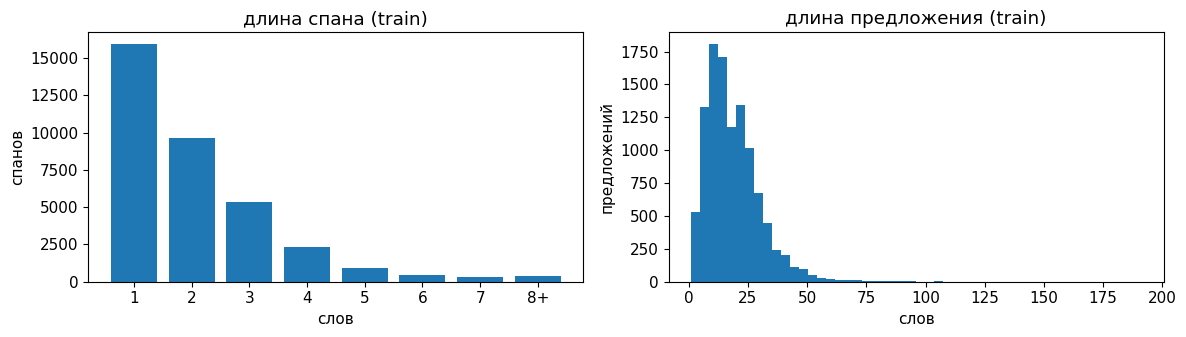

In [16]:
SPLITS = ['train', 'validation', 'test']
kept_counts = {split: collections.Counter(k for s in sentences[split] for _, _, k in s['spans']) for split in SPLITS}
source_counts = {split: collections.Counter(k for doc in docs[split] for _, _, k in parse_entities(doc['entities'])[0])
                 for split in SPLITS}
LONG_SPAN = 8
print('сущностей после конвертации, в скобках - в исходной разметке без разрывных, потеря - доля потерянных в train')
print(f'{"тип":<18}{"train":>14}{"val":>12}{"test":>12}{"потеря":>8}')
for kind, n in kept_counts['train'].most_common():
    row = [f'{kept_counts[s][kind]} ({source_counts[s][kind]})' for s in SPLITS]
    print(f'{kind:<18}{row[0]:>14}{row[1]:>12}{row[2]:>12}{1 - n / source_counts["train"][kind]:>8.0%}')
totals = [f'{sum(kept_counts[s].values())} ({sum(source_counts[s].values())})' for s in SPLITS]
print(f'{"всего":<18}{totals[0]:>14}{totals[1]:>12}{totals[2]:>12}'
      f'{1 - sum(kept_counts["train"].values()) / sum(source_counts["train"].values()):>8.0%}')

print()
for split in SPLITS:
    span_lengths = collections.Counter(min(e - s, LONG_SPAN) for sent in sentences[split] for s, e, _ in sent['spans'])
    sentence_lengths = np.array([len(s['tokens']) for s in sentences[split]])
    print(f'{split:<10} длина спана ({LONG_SPAN} = {LONG_SPAN}+): {dict(sorted(span_lengths.items()))}')
    print(f'{"":<10} длина предложения: медиана {np.median(sentence_lengths):.0f}, среднее {sentence_lengths.mean():.1f}, '
          f'95% {np.percentile(sentence_lengths, 95):.0f}, max {sentence_lengths.max()}, '
          f'без сущностей {sum(not s["spans"] for s in sentences[split])}')
    if split == 'train':
        train_span_lengths, train_sentence_lengths = span_lengths, sentence_lengths

train_spans = [(s, a, b, kind) for s in sentences['train'] for a, b, kind in s['spans']]
print(f'\nтипы спанов из {LONG_SPAN}+ слов в train:',
      collections.Counter(k for _, a, b, k in train_spans if b - a >= LONG_SPAN).most_common(3))
print('частые однословные EVENT в train:',
      collections.Counter(s['tokens'][a] for s, a, b, k in train_spans if k == 'EVENT' and b - a == 1).most_common(8))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
lengths = sorted(train_span_lengths)
axes[0].bar([str(k) if k < LONG_SPAN else f'{LONG_SPAN}+' for k in lengths], [train_span_lengths[k] for k in lengths])
axes[0].set(title='длина спана (train)', xlabel='слов', ylabel='спанов')
axes[1].hist(train_sentence_lengths, bins=50)
axes[1].set(title='длина предложения (train)', xlabel='слов', ylabel='предложений')
plt.tight_layout()
plt.show()

**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:** NEREL - это 933 новостных текста на русском, размеченных вручную в формате brat (Loukachevitch et al., 2021, [arXiv:2108.13112](https://arxiv.org/abs/2108.13112), [github](https://github.com/nerel-ds/NEREL)). Лицензия не указана ни в карточке на HF, ни в репозитории авторов, но датасет публичный и есть в списке в задании. Разметка богаче, чем в Collection3. Там 29 типов вместо трех, вложенные сущности, отношения и ссылки на Wikidata, для NER я беру только сущности.

После конвертации в train 10847 предложений и 35305 сущностей, в validation 1397 и 4440, в test 1492 и 4614. Чаще всего встречаются PERSON (7346 в train), PROFESSION (5186), EVENT (4271), ORGANIZATION (3762) и DATE (3545). Редкие типы - FAMILY (30), LANGUAGE (67), RELIGION (73, в validation всего 3), DISTRICT (101) и PERCENT (102), F1 по ним на validation будет очень шумным.

Больше половины спанов длиннее одного слова, 356 спанов в train длиной 8+ слов. Это в основном PROFESSION, LAW и ORGANIZATION, т е длинные должности, названия законов и организаций. Вложенных сущностей много, в train 9335 (21%) лежат внутри других и при переходе к плоскому BIO теряются. Сильнее всего это бьет по COUNTRY и RELIGION (теряется 49%) и по ORGANIZATION (35%), т к они часто стоят внутри других спанов. Часть типов похожа по смыслу - CITY / STATE_OR_PROVINCE / COUNTRY / LOCATION / DISTRICT, ORGANIZATION и PROFESSION в «пресс-служба МВД». EVENT часто размечен на глаголе, самые частые однословные EVENT в train это «скончался», «родился», «умер», «назначен». Такая сущность совсем не похожа на имя собственное. Предложения в среднем 18.7 слова (медиана 17, 95% до 39), так что до `MAX_LENGTH = 128` сабвордов почти ничего не обрезается.

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [17]:
def bio_to_spans(tags):
    spans, start, kind = [], None, None
    for i, tag in enumerate(list(tags) + ['O']):
        prefix, _, label = tag.partition('-')
        if start is not None and (prefix != 'I' or label != kind):
            spans.append((start, i, kind))
            start = None
        if prefix == 'B' or (prefix == 'I' and start is None):
            start, kind = i, label
    return spans


def spans_to_bio(spans, n_words):
    tags = ['O'] * n_words
    for start, end, kind in spans:
        tags[start] = f'B-{kind}'
        for i in range(start + 1, end):
            tags[i] = f'I-{kind}'
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    labels, previous = [], None
    for w in word_ids:
        if w is None:
            labels.append(-100)
        elif w != previous:
            labels.append(word_labels[w])
        elif b_to_i is None:
            labels.append(-100)
        else:
            labels.append(b_to_i.get(word_labels[w], word_labels[w]))
        previous = w
    return labels

In [18]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [19]:
tag_ids = {t: i for i, t in enumerate(LABEL_NAMES)}
features = datasets.Features({'tokens': datasets.Sequence(datasets.Value('string')),
                              'ner_tags': datasets.Sequence(datasets.ClassLabel(names=LABEL_NAMES))})


def sentences_to_dataset(items):
    tags = [[tag_ids[t] for t in spans_to_bio(s['spans'], len(s['tokens']))] for s in items]
    return datasets.Dataset.from_dict({'tokens': [s['tokens'] for s in items], 'ner_tags': tags}, features=features)


raw = DatasetDict({split: sentences_to_dataset(sentences[split]) for split in ['train', 'validation', 'test']})
print(raw)

n_surface_mismatch = sum(re.sub(r'\s', '', text) != ''.join(s['tokens'][a:b])
                         for split in sentences for s in sentences[split] for (a, b, _), text in zip(s['spans'], s['surface']))
print('спанов, где слова не совпали с исходным текстом сущности:', n_surface_mismatch)

DATA_DIR = Path('data')
DATA_DIR.mkdir(exist_ok=True)
for split in raw:
    path = DATA_DIR / f'{split}_spans.jsonl'
    with path.open('w', encoding='utf-8') as f:
        for ex in raw[split]:
            spans = bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
            f.write(json.dumps({'tokens': ex['tokens'], 'spans': spans}, ensure_ascii=False) + '\n')
    restored = [json.loads(line) for line in path.read_text(encoding='utf-8').splitlines()]
    n_same_bio = sum(spans_to_bio([tuple(s) for s in r['spans']], len(r['tokens'])) == [LABEL_NAMES[i] for i in ex['ner_tags']]
                     for r, ex in zip(restored, raw[split]))
    n_same_spans = sum([tuple(s) for s in r['spans']] == orig['spans'] for r, orig in zip(restored, sentences[split]))
    print(f'{path}: {len(restored)} предложений, BIO совпал {n_same_bio}, спаны совпали с исходными {n_same_spans}')
    assert n_same_bio == n_same_spans == len(raw[split])

for s in [s for s in sentences['train'] if len(s['spans']) >= 3][:2]:
    print('\n' + ' '.join(s['tokens']))
    for (a, b, kind), text in zip(s['spans'], s['surface']):
        print(f'  {kind:<14} [{a}, {b})  {" ".join(s["tokens"][a:b])!r}  в исходнике: {text!r}')

DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 10847
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 1397
    })
    test: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 1492
    })
})


спанов, где слова не совпали с исходным текстом сущности: 0


data/train_spans.jsonl: 10847 предложений, BIO совпал 10847, спаны совпали с исходными 10847
data/validation_spans.jsonl: 1397 предложений, BIO совпал 1397, спаны совпали с исходными 1397


data/test_spans.jsonl: 1492 предложений, BIO совпал 1492, спаны совпали с исходными 1492

БИШКЕК , 5 августа / Новости - Грузия / .
  CITY           [0, 1)  'БИШКЕК'  в исходнике: 'БИШКЕК'
  DATE           [2, 4)  '5 августа'  в исходнике: '5 августа'
  ORGANIZATION   [5, 8)  'Новости - Грузия'  в исходнике: 'Новости-Грузия'

Правоохранительные органы Киргизии обнаружили в доме , арендуемом гражданами США в Бишкеке , пулеметы , автоматы и снайперские винтовки , сообщает во вторник пресс - служба МВД Киргизии .
  ORGANIZATION   [0, 3)  'Правоохранительные органы Киргизии'  в исходнике: 'Правоохранительные органы Киргизии'
  NATIONALITY    [8, 10)  'гражданами США'  в исходнике: 'гражданами США'
  CITY           [11, 12)  'Бишкеке'  в исходнике: 'Бишкеке'
  DATE           [21, 23)  'во вторник'  в исходнике: 'во вторник'
  ORGANIZATION   [23, 28)  'пресс - служба МВД Киргизии'  в исходнике: 'пресс-служба МВД Киргизии'


In [20]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    n_truncated += len(enc['input_ids']) == MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

Map:   0%|          | 0/10847 [00:00<?, ? examples/s]

Map:   0%|          | 0/1397 [00:00<?, ? examples/s]

Map:   0%|          | 0/1492 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 10847
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 1397
    })
    test: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 1492
    })
})
ENTITY_TYPES ['AGE', 'AWARD', 'CITY', 'COUNTRY', 'CRIME', 'DATE', 'DISEASE', 'DISTRICT', 'EVENT', 'FACILITY', 'FAMILY', 'IDEOLOGY', 'LANGUAGE', 'LAW', 'LOCATION', 'MONEY', 'NATIONALITY', 'NUMBER', 'ORDINAL', 'ORGANIZATION', 'PENALTY', 'PERCENT', 'PERSON', 'PRODUCT', 'PROFESSION', 'RELIGION', 'STATE_OR_PROVINCE', 'TIME', 'WORK_OF_ART']


train: проверено 10838 предложений, обрезано по MAX_LENGTH 9, слов без сабвордов или за обрезкой 282
[CLS]            None  -100
Пуле                0  O
##меты              0  -100
,                   1  O
автоматы            2  O
и                   3  O
снайпер             4  O
##ские              4  -100
винтовки            5  O
изъяты              6  O
в                   7  O
аренду              8  O
##емом              8  -100
американцами        9  B-NATIONALITY
доме               10  O
в                  11  O
Бишкеке            12  B-CITY
[SEP]            None  -100


In [21]:
for split in SPLITS:
    n_cut = n_tail = n_no_subwords = n_lost_spans = 0
    for ex in data[split]:
        word_ids = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH).word_ids()
        covered = set(word_ids) - {None}
        cut = len(word_ids) == MAX_LENGTH
        n_cut += cut
        last = max(covered, default=-1)
        missing = [i for i in range(len(ex['tokens'])) if i not in covered]
        n_tail += sum(cut and i > last for i in missing)
        n_no_subwords += sum(not (cut and i > last) for i in missing)
        n_lost_spans += sum(any(i not in covered for i in range(a, b))
                            for a, b, _ in bio_to_spans([LABEL_NAMES[t] for t in ex['ner_tags']]))
    print(f'{split:<10} обрезано {n_cut:>2} предложений, слов в обрезанном хвосте {n_tail:>3}, '
          f'слов без сабвордов {n_no_subwords}, сущностей без метки {n_lost_spans}')

train      обрезано  9 предложений, слов в обрезанном хвосте 281, слов без сабвордов 1, сущностей без метки 41


validation обрезано  1 предложений, слов в обрезанном хвосте   4, слов без сабвордов 0, сущностей без метки 0


test       обрезано  1 предложений, слов в обрезанном хвосте  21, слов без сабвордов 0, сущностей без метки 2


**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:** Слово часто режется на несколько сабвордов, а тег нужен один на слово, поэтому метку получает первый сабворд, а остальные -100. Если размечать все куски, длинные слова получат больший вес в loss, а при предсказании придется выбирать между тегами разных кусков. Значение -100 это `ignore_index` в `CrossEntropyLoss`: такие позиции не входят ни в сумму, ни в знаменатель среднего, т е градиента от них нет. Так же помечены `[CLS]`, `[SEP]` и паддинг.

По `MAX_LENGTH = 128` в train обрезано 9 предложений из 10847, в validation одно и в test одно. В train без метки остались 281 слово из обрезанных хвостов (самое длинное предложение 191 слово) и одно слово без сабвордов. В test в обрезанный хвост попали 2 сущности из 4614, в validation ни одной. Они засчитаются как пропуски, т е recall на test теряет меньше 0.05%, на метрику это почти не влияет.

Основная работа была в конвертации, ее код в ячейке 2.1, тесты на игрушечном документе сразу после нее. NEREL дан целыми документами со спанами по символам, я сам режу текст на предложения и слова и перевожу спаны в BIO. Предложения режу без оглядки на разметку, чтобы разметка не подсказывала модели. Плоский BIO хранит один слой, поэтому из вложенных спанов я оставляю внешние, в train так ушло 9335 сущностей, а по всем сплитам 21%. 127 сущностей в train разрывные, т е собраны из нескольких кусков текста, их в BIO не записать, и они выброшены. Из двух пересекающихся, но не вложенных спанов (51 в train) оставляю тот, что начинается раньше. Еще 19 спанов по всем сплитам не совпали с границами слов, а 24 попали на границу двух предложений. 3 спана оказались точными дублями, и один размечен двумя типами - для него беру первый по алфавиту.

Мой токенизатор на слова режет по дефису, так что «пресс-служба» стала `пресс - служба`. Слова каждого спана я сравниваю с текстом сущности из самой brat-разметки (без пробелов), расхождений 0, т е офсеты и разбиение на слова согласованы. Невалидного BIO нет, т к я строю его сам из спанов, а запись в `data/<split>_spans.jsonl` и обратное чтение дают тот же BIO во всех трех сплитах.

---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [22]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [23]:
def fit_majority_tagger(tokens_list, tags_list):
    counts = collections.defaultdict(collections.Counter)
    for words, tags in zip(tokens_list, tags_list):
        for word, tag in zip(words, tags):
            counts[word][tag] += 1
    return {word: c.most_common(1)[0][0] for word, c in counts.items()}


def predict_majority(tagger, words):
    return [tagger.get(word, 'O') for word in words]

In [24]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

train_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['train']['ner_tags']]
majority = fit_majority_tagger(data['train']['tokens'], train_gold)
majority_pred = [predict_majority(majority, words) for words in val_tokens]

set_seed(SEED)
random_head_model = make_model()
random_head_pred = predict_word_tags(random_head_model, val_tokens)
del random_head_model

baseline = {'majority': entity_scores(val_gold, majority_pred), 'random_head': entity_scores(val_gold, random_head_pred)}
for name, scores in baseline.items():
    print(f'{name:<12}', {k: round(float(v), 4) for k, v in scores.items()})
print('случайная голова, частоты тегов:', collections.Counter(t for tags in random_head_pred for t in tags).most_common(5))
print('словарь, частоты тегов:', collections.Counter(t for tags in majority_pred for t in tags).most_common(5))

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

majority     {'f1_micro': 0.2845, 'f1_macro': 0.2419, 'precision': 0.2804, 'recall': 0.2887}
random_head  {'f1_micro': 0.0034, 'f1_macro': 0.003, 'precision': 0.002, 'recall': 0.0104}
случайная голова, частоты тегов: [('I-PERCENT', 2758), ('B-RELIGION', 2323), ('I-TIME', 1810), ('I-NATIONALITY', 1704), ('B-STATE_OR_PROVINCE', 1407)]
словарь, частоты тегов: [('O', 19123), ('I-DATE', 933), ('B-PROFESSION', 520), ('B-PERSON', 496), ('B-DATE', 424)]


In [25]:
train_word_tags = collections.defaultdict(collections.Counter)
for words, tags in zip(data['train']['tokens'], train_gold):
    for word, tag in zip(words, tags):
        train_word_tags[word][tag] += 1
for word in ['Москве', 'президент', 'России', 'Москвы', 'года']:
    print(f'{word:<10}', train_word_tags[word].most_common(3))


def entity_mentions(tokens_list, tags_list):
    return [(' '.join(words[a:b]), kind) for words, tags in zip(tokens_list, tags_list) for a, b, kind in bio_to_spans(tags)]


train_mentions = set(entity_mentions(data['train']['tokens'], train_gold))
val_mentions = entity_mentions(val_tokens, val_gold)
seen = [m in train_mentions for m in val_mentions]
single = [len(text.split()) == 1 for text, _ in val_mentions]
print(f'сущностей validation с тем же текстом и типом в train: {np.mean(seen):.0%}, '
      f'среди однословных {np.mean([s for s, one in zip(seen, single) if one]):.0%}, '
      f'среди многословных {np.mean([s for s, one in zip(seen, single) if not one]):.0%}')

Москве     [('B-CITY', 91), ('I-ORGANIZATION', 4), ('I-PROFESSION', 3)]
президент  [('B-PROFESSION', 135), ('I-PROFESSION', 25), ('O', 2)]
России     [('B-COUNTRY', 129), ('I-PROFESSION', 118), ('I-ORGANIZATION', 89)]
Москвы     [('I-PROFESSION', 23), ('I-ORGANIZATION', 21), ('B-CITY', 15)]
года       [('I-DATE', 1147), ('I-AWARD', 35), ('I-TIME', 33)]


сущностей validation с тем же текстом и типом в train: 36%, среди однословных 53%, среди многословных 22%


**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:** Словарный бейзлайн дает на validation F1 micro 0.285 и macro 0.242 (P 0.280, R 0.289). Он угадывает частые однословные сущности, которые повторяются из текста в текст с одним тегом - «Москве» в train 91 раз B-CITY, «президент» 135 раз B-PROFESSION. Но повторяются сущности не так уж часто: из сущностей validation с тем же текстом и типом в train есть 36%, среди многословных только 22%. К тому же больше половины спанов длиннее одного слова, а seqeval засчитывает спан только целиком. Контекста словарь не видит. «России» в train 129 раз B-COUNTRY и 118 раз внутри PROFESSION, а «Москвы» внутри PROFESSION и ORGANIZATION чаще, чем B-CITY. Для таких слов один тег на все случаи ломает границы.

Энкодер со случайной головой дает F1 0.003. Почти каждому слову он ставит какой-то тег сущности, чаще всего I-PERCENT, B-RELIGION и I-TIME, отсюда precision 0.002. Энкодер предобучен на MLM и дает осмысленные векторы, но голова `Linear(768, 59)` инициализирована случайно. Она умножает эти векторы на случайную матрицу, поэтому argmax по тегам тоже случайный. Связь вектора с тегом появляется только после обучения.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [26]:
from transformers import PrinterCallback

LR = 5e-5
BATCH_SIZE = 32
WARMUP = 0.1
WEIGHT_DECAY = 0.01
N_LOGS = 20


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    tok = tok or tokenizer
    for name, param in model.named_parameters():
        param.requires_grad = not freeze_encoder or name.startswith('classifier')
    total_steps = math.ceil(len(train_ds) / batch_size) * epochs
    log_every = max(1, total_steps // N_LOGS)
    args = TrainingArguments(
        output_dir=out_dir, num_train_epochs=epochs, learning_rate=lr,
        per_device_train_batch_size=batch_size, per_device_eval_batch_size=2 * batch_size,
        warmup_steps=WARMUP, weight_decay=WEIGHT_DECAY, lr_scheduler_type='linear',
        eval_strategy='steps', eval_steps=log_every, logging_steps=log_every,
        save_strategy='no', report_to='none', fp16=torch.cuda.is_available(), seed=SEED, disable_tqdm=True)
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                      data_collator=DataCollatorForTokenClassification(tok), processing_class=tok)
    trainer.remove_callback(PrinterCallback)
    start = time.perf_counter()
    trainer.train()
    total_seconds = time.perf_counter() - start
    trainer.accelerator.unwrap_model(model, keep_fp32_wrapper=False)   # снимает с forward обертку autocast от fp16, иначе fp32 в 6.4 считался бы в fp16
    eval_seconds = sum(h['eval_runtime'] for h in trainer.state.log_history if 'eval_runtime' in h)
    print(f'{out_dir}: всего {total_seconds:.0f} c, из них оценка на validation {eval_seconds:.0f} c')
    return trainer.state.log_history, total_seconds - eval_seconds

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

runs/main: всего 153 c, из них оценка на validation 29 c
обучение: 123.7 c на Tesla T4, 10847 предложений, 3 эпох(а)


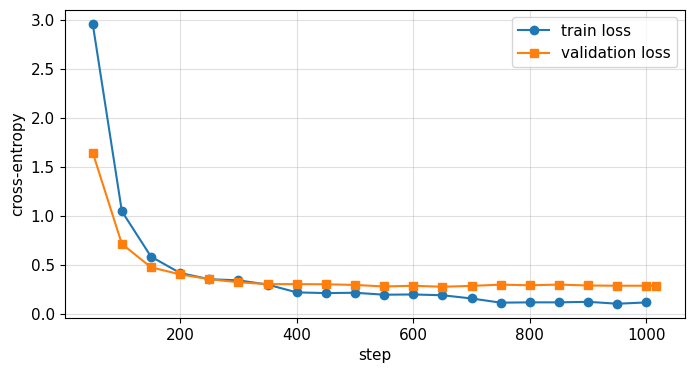

In [27]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

In [28]:
best_step, best_loss = min(eval_curve, key=lambda x: x[1])
print(f'eval loss: шаг {eval_curve[0][0]} -> {eval_curve[0][1]:.3f}, минимум на шаге {best_step} -> {best_loss:.3f}, '
      f'последний шаг {eval_curve[-1][0]} -> {eval_curve[-1][1]:.3f}')
print(f'train loss: первый лог {train_curve[0][1]:.3f}, последний {train_curve[-1][1]:.3f}')
steps_per_epoch = math.ceil(len(tokenized['train']) / BATCH_SIZE)
print(f'шагов на эпоху {steps_per_epoch}, точек eval loss {len(eval_curve)}')
for epoch in range(1, EPOCHS + 1):
    step, loss = min(eval_curve, key=lambda x: abs(x[0] - epoch * steps_per_epoch))
    print(f'эпоха {epoch} кончается на шаге {epoch * steps_per_epoch}, ближайшая оценка: шаг {step}, eval loss {loss:.3f}')
learning_rates = [(h['step'], h['learning_rate']) for h in history if 'learning_rate' in h]
print('learning rate по логам:', [(step, f'{lr:.1e}') for step, lr in learning_rates[:4]], '...', f'{learning_rates[-1][1]:.1e}')

eval loss: шаг 50 -> 1.646, минимум на шаге 650 -> 0.276, последний шаг 1017 -> 0.287
train loss: первый лог 2.960, последний 0.116
шагов на эпоху 339, точек eval loss 21
эпоха 1 кончается на шаге 339, ближайшая оценка: шаг 350, eval loss 0.303
эпоха 2 кончается на шаге 678, ближайшая оценка: шаг 700, eval loss 0.285
эпоха 3 кончается на шаге 1017, ближайшая оценка: шаг 1017, eval loss 0.287
learning rate по логам: [(50, '2.4e-05'), (100, '4.9e-05'), (150, '4.7e-05'), (200, '4.5e-05')] ... 9.8e-07


**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:** LR 5e-5 - верх обычного диапазона для base-моделей, т к эпох всего три, а голова на 59 тегов учится с нуля. Warmup на 10% шагов нужен, чтобы большие градиенты от случайной головы в первых шагах не испортили энкодер. По логам LR растет до 5e-5 примерно к шагу 100 и потом линейно падает. Batch 32 с fp16 спокойно помещается в T4 и дает 339 шагов на эпоху, weight decay 0.01 стандартный для BERT. Loss на validation считается каждые 50 шагов и в конце, всего 21 точка.

Eval loss падает с 1.646 на шаге 50 до минимума 0.276 на шаге 650, это конец второй эпохи (она кончается на шаге 678). К концу обучения он 0.287, а train loss все это время падает и в конце 0.116. Т е в третьей эпохе модель начинает запоминать train, но переобучение слабое - eval loss вырос всего на 0.01. Больше эпох не нужно, скорее хватило бы двух. Оговорка - я смотрю на loss, а F1 мог еще немного расти, для проверки нужен F1 по эпохам.

Обучение заняло 124 с на Tesla T4 (Kaggle), 1017 шагов. Еще 29 с ушло на оценку loss на validation по ходу обучения.

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [29]:
def token_f1(gold, pred):
    tp = fp = fn = 0
    for gold_tags, pred_tags in zip(gold, pred, strict=True):
        for g, p in zip(gold_tags, pred_tags, strict=True):
            if p != 'O' and p == g:
                tp += 1
                continue
            fp += p != 'O'
            fn += g != 'O'
    return 2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 0.0

In [30]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0


def evaluate_split(model, split, tok=None):
    tokens = [list(ws) for ws in data[split]['tokens']]
    gold = [[LABEL_NAMES[i] for i in tags] for tags in data[split]['ner_tags']]
    pred = predict_word_tags(model, tokens, tok=tok)
    report = classification_report(gold, pred, output_dict=True, zero_division=0)
    per_type = {k: {m: int(v) if m == 'support' else float(v) for m, v in report[k].items()}
                for k in ENTITY_TYPES if k in report}
    scores = dict(entity_scores(gold, pred), token_f1=token_f1(gold, pred), per_type=per_type)
    return scores, gold, pred


val_scores, _, val_pred = evaluate_split(model, 'validation')
final, test_gold, test_pred = evaluate_split(model, 'test')
for split, gold, pred in [('validation', val_gold, val_pred), ('test', test_gold, test_pred)]:
    print(f'=== {split}')
    print(classification_report(gold, pred, digits=3, zero_division=0))
print(f'{"":<10}{"F1 micro":>10}{"F1 macro":>10}{"token F1":>10}')
for split, scores in [('validation', val_scores), ('test', final)]:
    print(f'{split:<10}{scores["f1_micro"]:>10.4f}{scores["f1_macro"]:>10.4f}{scores["token_f1"]:>10.4f}')

=== validation


                   precision    recall  f1-score   support

              AGE      0.927     0.934     0.930       136
            AWARD      0.537     0.667     0.595        33
             CITY      0.807     0.918     0.859       159
          COUNTRY      0.905     0.848     0.876       191
            CRIME      0.338     0.411     0.371        56
             DATE      0.896     0.911     0.903       471
          DISEASE      0.550     0.649     0.595        94
         DISTRICT      0.000     0.000     0.000        11
            EVENT      0.589     0.603     0.596       632
         FACILITY      0.500     0.514     0.507        72
           FAMILY      0.000     0.000     0.000         6
         IDEOLOGY      0.571     0.640     0.604        25
         LANGUAGE      0.500     0.333     0.400         6
              LAW      0.500     0.526     0.513        38
         LOCATION      0.571     0.667     0.615        30
            MONEY      0.615     0.696     0.653       

                   precision    recall  f1-score   support

              AGE      0.938     0.903     0.920       134
            AWARD      0.686     0.737     0.711        95
             CITY      0.870     0.942     0.905       191
          COUNTRY      0.923     0.898     0.911       255
            CRIME      0.519     0.900     0.659        30
             DATE      0.884     0.900     0.892       482
          DISEASE      0.764     0.857     0.808        49
         DISTRICT      0.000     0.000     0.000        19
            EVENT      0.562     0.646     0.601       594
         FACILITY      0.581     0.705     0.637        61
           FAMILY      0.000     0.000     0.000         6
         IDEOLOGY      0.750     0.643     0.692        28
         LANGUAGE      1.000     0.625     0.769         8
              LAW      0.532     0.735     0.617        34
         LOCATION      0.636     0.553     0.592        38
            MONEY      0.775     0.756     0.765       

**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:** Хуже всего DISTRICT и FAMILY, у обоих F1 0 и на validation, и на test. Оба редкие (101 и 30 примеров в train, в test 19 и 6), а DISTRICT к тому же похож на CITY, STATE_OR_PROVINCE и LOCATION. Из частых типов хуже всего EVENT, F1 0.60 на test при 594 примерах. Он очень разный - это и «Вторая мировая война», и просто «умер» или «назначен», а спаны бывают длинные, и границу трудно угадать. В 5.1 видно, что EVENT дает больше половины всех пропусков.

На test F1 micro 0.819, macro 0.710 (на validation 0.808 и 0.659). Micro считает все спаны вместе, и его тянут вверх частые хорошо распознаваемые типы - PERSON (891 спан, F1 0.975), DATE (0.892), PROFESSION (0.821). Macro усредняет типы с равным весом, поэтому два нуля и слабые редкие типы опускают его на 0.1. На validation macro ниже еще и потому, что там хуже CRIME (0.371) и LANGUAGE (0.400). LANGUAGE и RELIGION там всего 6 и 3 спана, так что одна ошибка сильно меняет F1 типа.

Токенный F1 выше, 0.869 против 0.819 на test и 0.861 против 0.808 на validation. В токенном F1 спан засчитывается по частям. Если модель взяла «Максим Дадашев Дадашев» вместо «Максим Дадашев», два слова из трех верные, а для F1 по сущностям это сразу один false positive и один false negative. Пользователю NER нужна сущность целиком, половина имени или названия бесполезна, поэтому ближе к задаче F1 по сущностям.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [31]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def spans_overlap(a, b):
    return a[0] < b[1] and b[0] < a[1]


def categorize_errors(gold_spans, pred_spans):
    gold_spans = [tuple(g) for g in gold_spans]
    pred_spans = [tuple(p) for p in pred_spans]
    pred_set = set(pred_spans)
    result = []
    for g in gold_spans:
        if g in pred_set:
            result.append(('correct', g, g))
            continue
        hits = [p for p in pred_spans if spans_overlap(g, p)]
        same_type = [p for p in hits if p[2] == g[2]]
        if same_type:
            result.append(('boundary', g, same_type[0]))
        elif hits:
            result.append(('type', g, hits[0]))
        else:
            result.append(('missed', g, None))
    for p in pred_spans:
        if not any(spans_overlap(p, g) for g in gold_spans):
            result.append(('spurious', None, p))
    return result

In [32]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются

val_errors = [(i, c, g_span, p_span) for i, (gold_tags, pred_tags) in enumerate(zip(val_gold, val_pred))
              for c, g_span, p_span in categorize_errors(bio_to_spans(gold_tags), bio_to_spans(pred_tags))]
category_counts = collections.Counter(c for _, c, _, _ in val_errors)
errors = {c: category_counts[c] for c in ERROR_CATEGORIES}
n_errors = sum(n for c, n in errors.items() if c != 'correct')
for c in ERROR_CATEGORIES:
    share = f'{errors[c] / n_errors:6.1%} ошибок' if c != 'correct' else ''
    print(f'{c:<10}{errors[c]:>6}  {share}')

type_confusions = collections.Counter((g_span[2], p_span[2]) for _, c, g_span, p_span in val_errors if c == 'type')
print('частые ошибки типа (истинный -> предсказанный):', type_confusions.most_common(8))
missed_by_type = collections.Counter(g_span[2] for _, c, g_span, _ in val_errors if c == 'missed')
print('пропуски по типам:', missed_by_type.most_common(8))


def show_span(words, span):
    return 'None' if span is None else f'{span[2]} {" ".join(words[span[0]:span[1]])!r}'


rng = random.Random(SEED)
for c in ERROR_CATEGORIES[1:]:
    cases = [e for e in val_errors if e[1] == c]
    for i, _, g_span, p_span in rng.sample(cases, min(2, len(cases))):
        words = val_tokens[i]
        print(f'\n[{c}] {" ".join(words)}\n    gold: {show_span(words, g_span)}\n    pred: {show_span(words, p_span)}')

correct     3662  
boundary     308   29.4% ошибок
type         251   23.9% ошибок
missed       219   20.9% ошибок
spurious     271   25.8% ошибок
частые ошибки типа (истинный -> предсказанный): [(('FACILITY', 'ORGANIZATION'), 16), (('COUNTRY', 'NATIONALITY'), 14), (('ORGANIZATION', 'PERSON'), 10), (('ORGANIZATION', 'PROFESSION'), 9), (('ORGANIZATION', 'WORK_OF_ART'), 7), (('EVENT', 'CRIME'), 6), (('COUNTRY', 'ORGANIZATION'), 6), (('ORGANIZATION', 'PRODUCT'), 6)]
пропуски по типам: [('EVENT', 131), ('PROFESSION', 16), ('DATE', 12), ('CRIME', 11), ('DISEASE', 9), ('PENALTY', 8), ('NUMBER', 8), ('ORGANIZATION', 5)]

[boundary] Юкия Амано родился в японской префектуре Канагава на острове Хонсю в 1947 году — почти через два года после капитуляции Японии во Второй мировой войне и атомных бомбардировок страны .
    gold: DATE '1947 году'
    pred: DATE 'в 1947 году'

[boundary] Родившийся в Ленинграде 28 - летний Максим Дадашев Дадашев дебютировал в профессиональном боксе в 2016 году .
    g

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:** На validation 3662 спана найдены верно и 1049 ошибок. Чаще всего ошибка границы, boundary 308 (29%), дальше spurious 271 (26%), type 251 (24%) и missed 219 (21%).

В boundary модель обычно берет лишнее слово или теряет его на краю спана, например «в 1947 году» вместо «1947 году». В type путаются близкие по смыслу типы, FACILITY -> ORGANIZATION (16), COUNTRY -> NATIONALITY (14), ORGANIZATION -> PERSON (10), EVENT -> CRIME (6). Пропуски на 131 из 219 это EVENT, обычно нарицательные слова вроде «медицинских процедур», которые без правил разметки трудно отличить от обычного текста. В spurious модель находит то, что похоже на сущность, но не размечено, например «отменил победу» как EVENT или кусок «выраженные» из «слабо выраженные симптомы» как DISEASE.

Часть ошибок на самом деле в разметке. Предлог в датах размечен непоследовательно, «во вторник» в train входит в DATE целиком, а здесь gold «1947 году» без «в», так что модель наказана за разумный вариант. «Твиттеру» размечен как ORGANIZATION, но PRODUCT тоже разумно. В примере с «музыкантами группы СВ» gold только ORGANIZATION «СВ», а модель взяла всю PROFESSION. В train «музыкант» во всех 35 случаях стоит внутри PROFESSION, так что здесь скорее пропуск в разметке. «Максим Дадашев Дадашев» - это дубль фамилии в самом тексте.

Для ошибок границ я бы в первую очередь вернул вложенность, т е учил бы span-based голову или отдельный слой тегов для внутренних сущностей. Тогда модель не будет наказана за то, что нашла внешнюю сущность вместо внутренней или наоборот. Еще стоит посчитать, сколько предсказаний дают невалидные BIO-переходы, и если их много, добавить CRF поверх головы.

## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

In [33]:
import gc

ABLATION = 'freeze'   # 'freeze' или 'all_subwords'


def count_trainable(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


set_seed(SEED)
frozen_model = make_model()
frozen_history, frozen_seconds = train_ner(frozen_model, tokenized['train'], tokenized['validation'],
                                           freeze_encoder=True, out_dir='runs/freeze')
frozen_scores, _, _ = evaluate_split(frozen_model, 'validation')
frozen_trainable = count_trainable(frozen_model)
del frozen_model

FROZEN_HIGH_LR = 1e-3
set_seed(SEED)
frozen_high_model = make_model()
_, frozen_high_seconds = train_ner(frozen_high_model, tokenized['train'], tokenized['validation'], lr=FROZEN_HIGH_LR,
                                   freeze_encoder=True, out_dir='runs/freeze_high_lr')
frozen_high_scores, _, _ = evaluate_split(frozen_high_model, 'validation')
del frozen_high_model
gc.collect()
torch.cuda.empty_cache()

ablation = {
    'setting': ABLATION,
    'split': 'validation',
    'full': dict(f1_micro=val_scores['f1_micro'], f1_macro=val_scores['f1_macro'], token_f1=val_scores['token_f1'],
                 train_sec=train_seconds, trainable_params=count_trainable(model)),
    'frozen': dict(f1_micro=frozen_scores['f1_micro'], f1_macro=frozen_scores['f1_macro'], token_f1=frozen_scores['token_f1'],
                   train_sec=frozen_seconds, trainable_params=frozen_trainable),
    f'frozen_lr_{FROZEN_HIGH_LR:g}': dict(f1_micro=frozen_high_scores['f1_micro'], f1_macro=frozen_high_scores['f1_macro'],
                           token_f1=frozen_high_scores['token_f1'], train_sec=frozen_high_seconds,
                           trainable_params=frozen_trainable),
}
print(f'{"":<15}{"F1 micro":>10}{"F1 macro":>10}{"token F1":>10}{"сек":>8}{"обучаемых":>14}')
for name in ['full', 'frozen', f'frozen_lr_{FROZEN_HIGH_LR:g}']:
    r = ablation[name]
    print(f'{name:<15}{r["f1_micro"]:>10.4f}{r["f1_macro"]:>10.4f}{r["token_f1"]:>10.4f}{r["train_sec"]:>8.0f}{r["trainable_params"]:>14,}')
frozen_eval = [(h['step'], h['eval_loss']) for h in frozen_history if 'eval_loss' in h]
print('eval loss замороженного: начало', round(frozen_eval[0][1], 3), 'конец', round(frozen_eval[-1][1], 3))

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

runs/freeze: всего 67 c, из них оценка на validation 31 c


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

runs/freeze_high_lr: всего 67 c, из них оценка на validation 31 c


                 F1 micro  F1 macro  token F1     сек     обучаемых
full               0.8081    0.6593    0.8608     124   177,762,107
frozen             0.0710    0.0092    0.1183      37        45,371
frozen_lr_0.001    0.6460    0.4843    0.7509      37        45,371
eval loss замороженного: начало 4.047 конец 1.423


**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:** Выбрал `freeze`. LR тот же, 5e-5, и с замороженным энкодером F1 micro на validation 0.071 против 0.808 у полного дообучения, macro 0.009 против 0.659. Обучаемых параметров 45 тыс. против 177.8M, т е 0.03%. Обучение быстрее в 3.4 раза (37 с против 124 с), т к градиент не идет через энкодер.

При LR 5e-5 голова почти не сдвинулась, eval loss упал с 4.05 только до 1.42, а у полной модели он 0.29. Значит, для линейного слоя с нуля такой LR слишком мал, и я добавил прогон с замороженным энкодером и LR 1e-3. Он дает F1 0.646 и macro 0.484 за те же 37 с, т е признаки после MLM уже несут много информации о сущностях. Но разрыв 0.16 до полного дообучения показывает, что для точных границ и похожих типов энкодер тоже надо дообучать. LR 1e-3 я выбрал после первого прогона и смотрю на тот же validation, так что это маленький подбор на validation.

Вывод сделан по одному сиду и двум значениям LR. Дальше я бы прогнал несколько сидов и подобрал LR и число эпох для замороженного варианта. Так будет видно, это голова недоучилась или самих признаков не хватает.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:** ruBert-base за 3 эпохи (124 с на T4) дает на validation F1 micro 0.808 против 0.285 у словарного бейзлайна и 0.003 у случайной головы. На test у него micro 0.819 и macro 0.710. Хорошо распознаются PERSON (0.975), AGE, CITY, COUNTRY и DATE (0.89-0.92), плохо EVENT (0.60) и редкие DISTRICT и FAMILY (0). Чаще всего модель ошибается в границах спана (29% ошибок) и находит лишние спаны (26%). Главное ограничение в данных, а не в бюджете - плоский BIO теряет 21% сущностей, разметка EVENT и предлогов в датах непоследовательна, а eval loss перестает падать уже во второй эпохе. Замороженный энкодер даже с LR 1e-3 дает только 0.646, так что дообучать нужно всю модель. К сдвигу модель неустойчива, верхний регистр и транслит роняют F1 до 0.29 и 0.20 (6.3). Дальше я бы сделал NER с вложенностью (span-based голова), прогнал несколько сидов и добавил в train примеры в другом регистре.

### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [34]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))

{"track": "nlp", "model": "ai-forever/ruBert-base", "revision": "05f37a2ca9e333fd18f30cd0c96c68d274793c69", "dataset": "iluvvatar/NEREL", "classes": ["AGE", "AWARD", "CITY", "COUNTRY", "CRIME", "DATE", "DISEASE", "DISTRICT", "EVENT", "FACILITY", "FAMILY", "IDEOLOGY", "LANGUAGE", "LAW", "LOCATION", "MONEY", "NATIONALITY", "NUMBER", "ORDINAL", "ORGANIZATION", "PENALTY", "PERCENT", "PERSON", "PRODUCT", "PROFESSION", "RELIGION", "STATE_OR_PROVINCE", "TIME", "WORK_OF_ART"], "n_train": 10847, "n_val": 1397, "n_test": 1492, "params_total": 177762107, "ablation": {"setting": "freeze", "split": "valida
final F1 micro 0.8191


In [35]:
BONUS = {}


def measure_latency(model, batch, n_runs=20, n_warmup=3):
    with torch.inference_mode():
        for _ in range(n_warmup):
            model(**batch)
        if batch['input_ids'].device.type == 'cuda':
            torch.cuda.synchronize()
        start = time.perf_counter()
        for _ in range(n_runs):
            model(**batch)
        if batch['input_ids'].device.type == 'cuda':
            torch.cuda.synchronize()
    return (time.perf_counter() - start) / n_runs * 1000

---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [36]:
if '6.1' in BONUS_TASKS:
    # ваш код
    pass

**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:** Не делал.

## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [37]:
if '6.2' in BONUS_TASKS:
    SMALL_ID, SMALL_REVISION, SMALL_LR = 'cointegrated/rubert-tiny2', 'e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae', 2e-4
    small_tokenizer = AutoTokenizer.from_pretrained(SMALL_ID, revision=SMALL_REVISION)
    small_tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names,
                               fn_kwargs=dict(tok=small_tokenizer))
    set_seed(SEED)
    small_model = make_model(SMALL_ID, SMALL_REVISION)
    _, small_seconds = train_ner(small_model, small_tokenized['train'], small_tokenized['validation'], lr=SMALL_LR,
                                 tok=small_tokenizer, out_dir='runs/tiny')
    small_scores, _, _ = evaluate_split(small_model, 'test', tok=small_tokenizer)

    latency_words = val_tokens[:64]
    comparison = {}
    for name, m, tok, seconds, scores in [(MODEL_ID, model, tokenizer, train_seconds, final),
                                          (SMALL_ID, small_model, small_tokenizer, small_seconds, small_scores)]:
        m.to(device).eval()
        batch = {k: v.to(device) for k, v in tok(latency_words, is_split_into_words=True, truncation=True,
                                                   max_length=MAX_LENGTH, padding=True, return_tensors='pt').items()}
        if device.type == 'cuda':
            torch.cuda.synchronize()
            torch.cuda.reset_peak_memory_stats()
        allocated = torch.cuda.memory_allocated() if device.type == 'cuda' else 0
        latency = measure_latency(m, batch)
        activations_mb = (torch.cuda.max_memory_allocated() - allocated) / 2**20 if device.type == 'cuda' else 0.0
        comparison[name] = dict(params=count_params(m), size_mb=count_params(m) * 4 / 2**20, train_sec=seconds,
                                latency_ms_64=latency, activations_mb_64=activations_mb, f1_micro=scores['f1_micro'],
                                f1_macro=scores['f1_macro'], token_f1=scores['token_f1'])
    del small_model
    gc.collect()
    torch.cuda.empty_cache()
    BONUS['6.2'] = comparison
    print('инференс на 64 предложениях validation, память - сверх весов, пик на GPU')
    print(f'{"модель":<28}{"парам":>13}{"MB fp32":>9}{"обуч, с":>9}{"мс":>8}{"память, MB":>12}{"F1 micro":>10}{"F1 macro":>10}')
    for name, r in comparison.items():
        print(f'{name:<28}{r["params"]:>13,}{r["size_mb"]:>9.0f}{r["train_sec"]:>9.0f}{r["latency_ms_64"]:>8.1f}'
              f'{r["activations_mb_64"]:>12.0f}{r["f1_micro"]:>10.4f}{r["f1_macro"]:>10.4f}')

config.json:   0%|          | 0.00/693 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/401 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.08M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.74M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Map:   0%|          | 0/10847 [00:00<?, ? examples/s]

... (3 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

runs/tiny: всего 32 c, из них оценка на validation 7 c


инференс на 64 предложениях validation, память - сверх весов, пик на GPU
модель                              парам  MB fp32  обуч, с      мс  память, MB  F1 micro  F1 macro
ai-forever/ruBert-base        177,762,107      678      124   311.1         155    0.8191    0.7100
cointegrated/rubert-tiny2      29,114,579      111       25    14.6          46    0.6985    0.4892


**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:** Сравнил с `cointegrated/rubert-tiny2`. Он в 6 раз меньше - 29.1M параметров и 111 MB против 177.8M и 678 MB. Учится в 4.9 раза быстрее (25 с против 124 с), а на инференсе 64 предложений на T4 быстрее в 21 раз (14.6 мс против 311.1 мс). Памяти сверх весов на этот инференс ему нужно 46 MB против 155 MB. Но F1 на test заметно ниже, micro 0.699 против 0.819, macro 0.489 против 0.710. Macro падает почти вдвое сильнее micro, т е маленькая модель хуже всего справляется с редкими типами. Т е base лучше по качеству, но тяжелее и медленнее, а tiny имеет смысл, если важна скорость.

Сравнение честное в том смысле, что данные, сплиты и конвертация те же. Совпадают 3 эпохи, batch 32, warmup, weight decay, `MAX_LENGTH` и сид, оценка тоже одна - по словам через `predict_word_tags` на test. Токенизатор у каждой модели свой, и LR разный, 2e-4 у tiny против 5e-5 у base, т к маленьким моделям нужен больший LR. Ни один LR я не подбирал, и прогон один, поэтому разницу в 0.01 я бы всерьез не принимал, но разрыв 0.12 по micro явно больше шума.

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

In [38]:
TRANSLIT = dict(zip('абвгдеёжзийклмнопрстуфхцчшщъыьэюя',
                    ['a', 'b', 'v', 'g', 'd', 'e', 'e', 'zh', 'z', 'i', 'y', 'k', 'l', 'm', 'n', 'o', 'p', 'r', 's', 't',
                     'u', 'f', 'kh', 'ts', 'ch', 'sh', 'shch', '', 'y', '', 'e', 'yu', 'ya']))


def transliterate_char(ch):
    latin = TRANSLIT.get(ch.lower())
    if latin is None:
        return ch
    return latin.capitalize() if ch.isupper() else latin


def transliterate(word):
    return ''.join(transliterate_char(ch) for ch in word)


def add_typo(word, rng):
    if len(word) < 4 or not word.isalpha():
        return word
    i = rng.randrange(1, len(word) - 1)
    if rng.random() < 0.5:
        return word[:i] + word[i + 1] + word[i] + word[i + 2:]
    return word[:i] + word[i + 1:]


TYPO_RATE = 0.3


def corrupt(tokens_list, kind, seed=SEED):
    rng = random.Random(seed)
    if kind == 'lower':
        return [[w.lower() for w in ws] for ws in tokens_list]
    if kind == 'upper':
        return [[w.upper() for w in ws] for ws in tokens_list]
    if kind == 'translit':
        return [[transliterate(w) for w in ws] for ws in tokens_list]
    if kind == 'typos':
        return [[add_typo(w, rng) if rng.random() < TYPO_RATE else w for w in ws] for ws in tokens_list]
    if kind == 'clean':
        return tokens_list
    raise ValueError(f'неизвестная порча {kind}')


if '6.3' in BONUS_TASKS:
    shift = {}
    for kind in ['clean', 'lower', 'upper', 'typos', 'translit']:
        corrupted = corrupt(val_tokens, kind)
        shift[kind] = entity_scores(val_gold, predict_word_tags(model, corrupted))
        print(f'{kind:<9} F1 micro {shift[kind]["f1_micro"]:.4f}  P {shift[kind]["precision"]:.4f}  '
              f'R {shift[kind]["recall"]:.4f}   пример: {" ".join(corrupted[1][:10])}')
    sample = val_tokens[1][:10]
    for kind in ['clean', 'lower', 'upper', 'translit']:
        print(kind, tokenizer(corrupt([sample], kind)[0], is_split_into_words=True).tokens()[1:-1])
    BONUS['6.3'] = shift

clean     F1 micro 0.8081  P 0.7921  R 0.8248   пример: Барак Обама


lower     F1 micro 0.6852  P 0.7039  R 0.6676   пример: барак обама


upper     F1 micro 0.2904  P 0.4479  R 0.2149   пример: БАРАК ОБАМА


typos     F1 micro 0.7284  P 0.7257  R 0.7311   пример: Брак Обаа


translit  F1 micro 0.2046  P 0.4081  R 0.1365   пример: Barak Obama
clean ['Барак', 'Обама']
lower ['барак', 'оба', '##ма']
upper ['БАР', '##АК', 'ОБ', '##АМ', '##А']
translit ['Bar', '##ak', 'Ob', '##ama']


**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:** Чистый validation дает F1 0.808. Транслит роняет его до 0.205, верхний регистр до 0.290, нижний регистр до 0.685, а опечатки (в 30% слов от 4 букв переставлена или удалена буква) до 0.728.

Сильнее всего бьют транслит и верхний регистр, т к токенизатор регистрозависимый и от порчи ломаются сабворды. «Барак Обама» в чистом тексте это два целых слова, в транслите уже `Bar ##ak Ob ##ama`, а в верхнем регистре `БАР ##АК ОБ ##АМ ##А`. Латиница в русских новостях редкая, в основном в названиях компаний, к тому же пропадают русские окончания, по которым модель видит падеж и границы. Капсом в новостях пишут в основном аббревиатуры (МВД, США), так что главный признак имени собственного пропадает, и recall падает до 0.21. Нижний регистр убирает только заглавные буквы, precision держится на 0.70, т е модель во многом опирается на контекст. Но «обама» режется в `оба ##ма`, и имя становится похоже на обычные слова. Опечатки меньше всего меняют форму слова и не трогают регистр, поэтому они самые мягкие.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [39]:
import warnings


def state_size_mb(model):
    path = Path('runs') / 'size_check.pt'
    path.parent.mkdir(exist_ok=True)
    torch.save(model.state_dict(), path)
    size = path.stat().st_size / 2**20
    path.unlink()
    return size


def quantize_encoder(model, qconfig_spec):
    quantized = copy.deepcopy(model)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', DeprecationWarning)
        quantized.base_model.encoder = torch.ao.quantization.quantize_dynamic(
            quantized.base_model.encoder, qconfig_spec, dtype=torch.qint8)
    return quantized


def speed_batch(n, dev):
    enc = tokenizer(val_tokens[:n], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH,
                    padding=True, return_tensors='pt')
    return {k: v.to(dev) for k, v in enc.items()}


if '6.4' in BONUS_TASKS:
    CPU_BATCH, GPU_BATCH = 32, 128
    fp32_model = copy.deepcopy(model).cpu().eval()
    variants = [('cpu_fp32', fp32_model),
                ('cpu_int8_encoder', quantize_encoder(fp32_model, {torch.nn.Linear})),
                ('cpu_int8_per_channel', quantize_encoder(
                    fp32_model, {torch.nn.Linear: torch.ao.quantization.per_channel_dynamic_qconfig}))]
    speed = {}
    cpu_batch = speed_batch(CPU_BATCH, torch.device('cpu'))
    for name, m in variants:
        scores = entity_scores(val_gold, predict_word_tags(m, val_tokens, dev=torch.device('cpu')))
        speed[name] = dict(batch=CPU_BATCH, latency_ms=measure_latency(m, cpu_batch, n_runs=10),
                           size_mb=state_size_mb(m), **scores)
    del variants, fp32_model
    if device.type == 'cuda':
        gpu_batch = speed_batch(GPU_BATCH, device)
        fp16_model = copy.deepcopy(model).to(device).half().eval()
        for name, m in [('gpu_fp32', model.to(device).eval()), ('gpu_fp16', fp16_model)]:
            scores = entity_scores(val_gold, predict_word_tags(m, val_tokens))
            speed[name] = dict(batch=GPU_BATCH, latency_ms=measure_latency(m, gpu_batch), size_mb=state_size_mb(m), **scores)
        del fp16_model
    BONUS['6.4'] = speed
    print(f'CPU потоков: {torch.get_num_threads()}, F1 на всей validation')
    print(f'{"вариант":<22}{"батч":>6}{"мс / батч":>10}{"MB":>8}{"F1 micro":>10}')
    for name, r in speed.items():
        print(f'{name:<22}{r["batch"]:>6}{r["latency_ms"]:>10.1f}{r["size_mb"]:>8.0f}{r["f1_micro"]:>10.4f}')

CPU потоков: 2, F1 на всей validation
вариант                 батч мс / батч      MB  F1 micro
cpu_fp32                  32    1583.4     678    0.8081
cpu_int8_encoder          32    1416.6     435    0.6812
cpu_int8_per_channel      32    1434.5     437    0.6842
gpu_fp32                 128     582.3     678    0.8081
gpu_fp16                 128     134.9     339    0.8081


**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:** На CPU (Kaggle, 2 потока, batch 32) динамическая int8-квантизация Linear-слоев энкодера дает всего 1.12x, 1583 мс -> 1417 мс. Размер падает с 678 до 435 MB, но F1 на validation проседает с 0.808 до 0.681. Квантизация весов по каналам почти ничего не меняет (F1 0.684), так что дело не в весах, а скорее в квантизации активаций. На GPU T4 (batch 128) перевод в fp16 ускоряет в 4.3 раза, 582 мс -> 135 мс, размер вдвое меньше (339 MB), а F1 не меняется (0.808). Замер везде на одном батче, 3 прогрева, среднее по 10 запускам на CPU и 20 на GPU.

Это из-за того, как устроен ruBert. 52% параметров в эмбеддингах, а это таблица, из которой просто берутся строки, вычислений там нет. Поэтому квантизация энкодера уменьшила размер только на 243 MB, и модели, у которой почти все параметры в словаре, такой прием мало даст. Все вычисления идут в 12 слоях энкодера. Динамическая квантизация на каждом вызове заново квантует активации одной шкалой на весь тензор, а attention-матмулы и softmax остаются в fp32, поэтому и всего 1.12x. Падение F1 я объясняю тем же - в активациях BERT бывают большие выбросы, и одна шкала на тензор их плохо передает, но до конца я это не проверял. На T4 есть тензорные ядра под fp16, поэтому там ускорение большое и без потерь.

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

mean  порог 0: F1 0.8081 (P 0.7921, R 0.8248) | лучший порог 0.76: F1 0.8260 (P 0.8778, R 0.7800)
min   порог 0: F1 0.8081 (P 0.7921, R 0.8248) | лучший порог 0.71: F1 0.8280 (P 0.8841, R 0.7786)
проверка: F1 при пороге 0 совпадает с seqeval 0.8081


test, mean: F1 при пороге 0 0.8191, при пороге 0.76 0.8253
test, min: F1 при пороге 0 0.8191, при пороге 0.71 0.8287


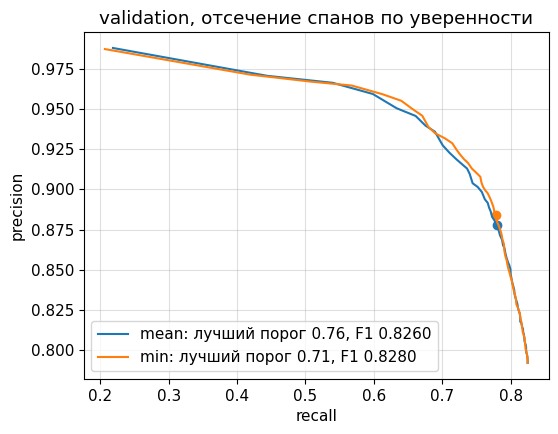

In [40]:
if '6.5' in BONUS_TASKS:
    tags_with_probs, word_probs = predict_word_tags(model, val_tokens, return_probs=True)
    gold_sets = [set(bio_to_spans(tags)) for tags in val_gold]
    scored = []
    for i, (tags, probs) in enumerate(zip(tags_with_probs, word_probs)):
        for start, end, kind in bio_to_spans(tags):
            span_probs = probs[start:end]
            scored.append((i, (start, end, kind), sum(span_probs) / len(span_probs), min(span_probs)))
    n_gold = sum(len(s) for s in gold_sets)
    hits = np.array([span in gold_sets[i] for i, span, _, _ in scored])
    thresholds = np.round(np.linspace(0, 0.99, 100), 2)
    curves = {}
    for agg, column in [('mean', 2), ('min', 3)]:
        conf = np.array([row[column] for row in scored])
        rows = []
        for thr in thresholds:
            keep = conf >= thr
            tp = int(hits[keep].sum())
            precision = tp / keep.sum() if keep.sum() else 0.0
            recall = tp / n_gold
            f1 = 2 * precision * recall / (precision + recall) if tp else 0.0
            rows.append((float(thr), precision, recall, f1))
        curves[agg] = rows
    plt.figure(figsize=(6, 4.5))
    BONUS['6.5'] = {}
    for agg, rows in curves.items():
        best = max(rows, key=lambda r: r[3])
        BONUS['6.5'][agg] = dict(best_threshold=best[0], best_f1=best[3], f1_at_0=rows[0][3],
                                 precision=best[1], recall=best[2])
        plt.plot([r[2] for r in rows], [r[1] for r in rows], label=f'{agg}: лучший порог {best[0]:.2f}, F1 {best[3]:.4f}')
        plt.scatter([best[2]], [best[1]])
        print(f'{agg:<5} порог 0: F1 {rows[0][3]:.4f} (P {rows[0][1]:.4f}, R {rows[0][2]:.4f}) | '
              f'лучший порог {best[0]:.2f}: F1 {best[3]:.4f} (P {best[1]:.4f}, R {best[2]:.4f})')
    print('проверка: F1 при пороге 0 совпадает с seqeval', round(f1_score(val_gold, tags_with_probs), 4))
    test_tags, test_probs = predict_word_tags(model, [list(ws) for ws in data['test']['tokens']], return_probs=True)
    for agg, reduce in [('mean', lambda p: sum(p) / len(p)), ('min', min)]:
        threshold = BONUS['6.5'][agg]['best_threshold']
        filtered = [spans_to_bio([s for s in bio_to_spans(tags) if reduce(probs[s[0]:s[1]]) >= threshold], len(tags))
                    for tags, probs in zip(test_tags, test_probs)]
        BONUS['6.5'][agg]['test_f1_at_0'] = f1_score(test_gold, test_tags)
        BONUS['6.5'][agg]['test_f1_at_best'] = f1_score(test_gold, filtered)
        print(f'test, {agg}: F1 при пороге 0 {BONUS["6.5"][agg]["test_f1_at_0"]:.4f}, '
              f'при пороге {threshold:.2f} {BONUS["6.5"][agg]["test_f1_at_best"]:.4f}')
    plt.xlabel('recall')
    plt.ylabel('precision')
    plt.title('validation, отсечение спанов по уверенности')
    plt.legend()
    plt.grid(True, alpha=0.4)
    plt.show()

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:** На validation лучший порог по средней уверенности 0.76, F1 0.826 против 0.808 при пороге 0 (+0.018). Precision растет с 0.792 до 0.878, recall падает с 0.825 до 0.780. По минимальной уверенности лучший порог 0.71, F1 0.828 (+0.020). Пороги я подбирал на validation и потом применил к test, там прирост меньше, но есть - 0.819 -> 0.825 для средней и 0.819 -> 0.829 для минимальной.

Средняя уверенность сглаживает, и если в длинном спане одно слово сомнительное, остальные его вытянут. Минимальная смотрит на самое слабое слово спана и строже отсекает спаны, в которых модель сомневается хоть в одном слове. По F1 разница между ними 0.002, это в пределах шума одного прогона.

Порог не может поднять recall, т к он только выкидывает предсказанные спаны и не добавляет новых. Число верно найденных спанов от этого может только уменьшиться, а число истинных спанов не меняется.

In [41]:
if BONUS:
    (ARTIFACTS / 'bonus.json').write_text(json.dumps(json_ready(BONUS), ensure_ascii=False, indent=2), encoding='utf-8')
    print('сохранено', sorted(BONUS))

сохранено ['6.2', '6.3', '6.4', '6.5']
